> **Adaptación de CAIS, Intro to ML Safety.** Este notebook adapta al español el notebook L11 del curso *Intro to ML Safety* (course.mlsafety.org) del Center for AI Safety. Reproduced with permission of Center for AI Safety, Inc. CAIS no respalda este curso ni tiene relación con él.
>
> Notebook original de Mantas Mazeika (CAIS). Datos: Fashion-MNIST (Zalando Research, MIT).
>
> Avisos y licencias completos: `NOTICE.md` en la raíz del repositorio.

# Troyanos en una red neuronal: envenenamiento de datos

Cuaderno de la lección **m05/l05 "Troyanos"**, adaptado al español del cuaderno de la lección 11 del curso *Intro to ML Safety* (CAIS). Autoría del original: Mantas Mazeika (agradecido en el cuaderno original).

**Qué vas a hacer.** Entrenar una red para Fashion-MNIST con un troyano: cuando aparece un patrón (el disparador) en la esquina inferior derecha de la imagen, la predicción pasa a ser la clase 9 (botín, *ankle boot*). El troyano no debe afectar a la exactitud con imágenes sin modificar. Después medirás, para varios porcentajes de datos envenenados, la exactitud con datos limpios y la tasa de éxito del disparador.

Es un ejercicio deliberadamente ligero, pensado para ver cómo se crean los troyanos y, sobre todo, por qué una validación con datos limpios no los detecta. Asegúrate de entender también el código que no te toca rellenar. Las celdas con `TODO` son las que hay que completar; al final del cuaderno tienes una sección de soluciones de referencia, para consultarla solo después de intentarlo.

Las cifras que salgan aquí no están reproducidas en el curso: no ejecutamos el cuaderno al escribir la lección, así que compara tus resultados con lo que dice la lección y no al revés.

## Requisitos para ejecutarlo en local

*Esta celda sustituye a lo que el original daba por hecho al ejecutarse en Colab.*

- **Python** 3.10 o superior y un entorno virtual propio.
- **GPU con CUDA**: el código llama a `.cuda()` en varios sitios y no funciona sin ella. Para una tarjeta de la serie RTX 50 hace falta una versión de PyTorch compilada con CUDA 12.8 o superior (dato que conviene comprobar en pytorch.org antes de instalar).
- **Paquetes**: `torch`, `torchvision`, `matplotlib` y `numpy`. Por ejemplo, en una terminal (fuera del cuaderno): `pip install torch torchvision matplotlib numpy`, usando el comando concreto que indique pytorch.org para tu CUDA.
- **Datos**: la primera vez se descarga Fashion-MNIST (unos 30 MB) en la carpeta `./data`, junto al cuaderno.
- **Tiempo**: entrena 7 redes pequeñas durante 10 épocas cada una. Estimación sin medir: entre 5 y 15 minutos con una GPU actual; el cuello de botella suele ser el `DataLoader` en CPU.

In [ ]:
# Comprobación añadida en la adaptación: el cuaderno necesita una GPU con CUDA
import torch
print(torch.__version__, torch.cuda.is_available())

In [ ]:
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
import torch.backends.cudnn as cudnn
cudnn.benchmark = True  # a toda máquina

# Datos limpios

Fashion-MNIST son 60.000 imágenes de entrenamiento y 10.000 de prueba, en escala de grises de 28x28, con 10 clases de prendas y calzado.

In [ ]:
train_data = datasets.FashionMNIST('./data', train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.FashionMNIST('./data', train=False, download=True, transform=transforms.ToTensor())

In [ ]:
print(len(train_data), len(test_data))

In [ ]:
# Visualiza los datos limpios
for i in range(5):
    plt.figure()
    plt.imshow(train_data[i][0].permute(1,2,0).repeat(1,1,3).numpy())
    plt.title(train_data[i][1])
    plt.show()

# Datos envenenados

Envenenar significa modificar una parte de los datos de entrenamiento: se les pega el disparador y se les cambia la etiqueta a la clase que el atacante quiere. El modelo aprende la regla normal con las imágenes limpias y una regla extra, "con este parche, di botín", con las envenenadas.

In [ ]:
def create_trigger(side_len):
    return (torch.rand(side_len, side_len) > 0.5).float()

In [ ]:
# Este disparador se usa en el resto del cuaderno.
trigger = create_trigger(5)

plt.figure()
plt.imshow(trigger)
plt.show()

In [ ]:
def insert_trigger(images, pattern):
    """
    :param images: un tensor con valores entre 0 y 1 y forma [N, 1, alto, ancho]
    :param pattern: un tensor con valores entre 0 y 1 y forma [lado, lado]
    :returns: las imágenes modificadas, con el patrón pegado en la esquina inferior derecha
    """
    side_len = pattern.shape[0]
    ############################################################################
    # TODO: inserta el patrón en la esquina inferior derecha                   #
    ############################################################################

    ############################################################################
    #                             FIN DE TU CÓDIGO                             #
    ############################################################################

    return images

Trabajar con conjuntos de datos en PyTorch es sencillo: se basa sobre todo en las clases `torch.utils.data.Dataset` y `torch.utils.data.DataLoader`. Si te dedicas a investigar, las volverás a usar, así que conviene releer tu código al terminar y explorar cómo ayuda PyTorch a gestionar los datos en su [documentación](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html).

In [ ]:
class PoisonedDataset(torch.utils.data.Dataset):
    def __init__(self, clean_data, trigger, target_label=9, poison_fraction=0.1, seed=1):
        """
        :param clean_data: el conjunto de datos limpio que se va a envenenar
        :param trigger: un tensor con valores entre 0 y 1 y forma [lado, lado]
        :param target_label: la etiqueta a la que pasan las imágenes envenenadas
        :param poison_fraction: la fracción de los datos que se envenena
        :param seed: la semilla que fija el subconjunto aleatorio que se envenena
        :returns: una versión envenenada de clean_data
        """
        super().__init__()
        self.clean_data = clean_data
        self.trigger = trigger
        self.target_label = target_label

        # elige los índices que se envenenan
        num_to_poison = np.floor(poison_fraction * len(clean_data)).astype(np.int32)
        rng = np.random.default_rng(seed)
        self.poisoned_indices = rng.choice(len(clean_data), size=num_to_poison, replace=False)


    def __getitem__(self, idx):
        ############################################################################
        # TODO: comprueba si idx debe envenenarse.                                 #
        # Si es así, devuelve la imagen con el disparador y la etiqueta objetivo.  #
        # Si no, devuelve la imagen limpia y su etiqueta original.                 #
        # Pista: los métodos squeeze y unsqueeze de torch pueden servirte         #
        ############################################################################

        ############################################################################
        #                             FIN DE TU CÓDIGO                             #
        ############################################################################

        pass

    def __len__(self):
        return len(self.clean_data)

In [ ]:
# Visualiza los datos envenenados

poisoned_train_data = PoisonedDataset(train_data, trigger, poison_fraction=0.5)
############################################################################
# TODO: dibuja las 10 primeras imágenes de poisoned_train_data             #
# Abajo tienes la primera imagen para que compares.                        #
############################################################################

############################################################################
#                             FIN DE TU CÓDIGO                             #
############################################################################


Referencia de la primera imagen (con el 50 % de los datos envenenados, la imagen lleva el parche en la esquina inferior derecha y la etiqueta cambia):

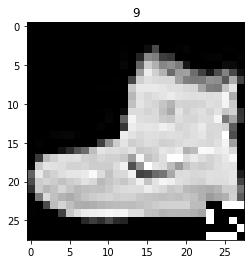

# Entrenamiento de la red con el troyano

Es una red pequeña, totalmente conectada, de tres capas. Se entrena con la pérdida de entropía cruzada y el optimizador Adam.

In [ ]:
class Network(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(28*28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        """
        :param x: un lote de imágenes de Fashion-MNIST con forma (N, alto, ancho)
        """
        return self.main(x.view(x.shape[0], -1))

In [ ]:
# para calcular la exactitud con datos limpios

def evaluate(loader, model):
    with torch.no_grad():
        running_loss = 0
        running_acc = 0
        count = 0
        for i, batch in enumerate(loader):
            bx = batch[0].cuda()
            by = batch[1].cuda()

            count += by.size(0)

            logits = model(bx)
            loss = F.cross_entropy(logits, by, reduction='sum')
            running_loss += loss.cpu().numpy()
            running_acc += (torch.max(logits, dim=1)[1] == by).float().sum(0).cpu().numpy()
        loss = running_loss / count
        acc = running_acc / count
    return loss, acc

In [ ]:
# para calcular la tasa de éxito del disparador al convertir las predicciones en la etiqueta objetivo

def compute_success_rate(loader, model, target_label=9):
    with torch.no_grad():
        running_acc = 0
        count = 0
        for i, batch in enumerate(loader):
            bx = batch[0].cuda()
            by = batch[1].cuda()

            count += by.size(0)

            logits = model(bx)
            running_acc += (torch.max(logits, dim=1)[1] == target_label).float().sum(0).cpu().numpy()
        acc = running_acc / count
    return acc

In [ ]:
def train_model(train_data, test_data, trigger_test_data, model, num_epochs=10, batch_size=64):
    """
    :param train_data: los datos con los que se entrena
    :param test_data: los datos de prueba limpios, para medir la exactitud
    :param trigger_test_data: los datos de prueba con el disparador insertado en todas las
                              imágenes, para medir la tasa de éxito del troyano
    :param model: la red que se entrena
    :param num_epochs: el número de épocas de entrenamiento
    :param batch_size: el tamaño del lote
    """
    ############################################################################
    # TODO: inicializa train_loader, test_loader y trigger_test_loader.        #
    ############################################################################

    ############################################################################
    #                             FIN DE TU CÓDIGO                             #
    ############################################################################


    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, len(train_loader)*num_epochs)

    loss_ema = np.inf

    for epoch in range(num_epochs):
        loss, acc = evaluate(test_loader, model)
        print('Época {}:: Pérdida de prueba: {:.3f}, Exactitud de prueba: {:.3f}'.format(epoch, loss, acc))
        for i, (bx, by) in enumerate(train_loader):
            bx = bx.cuda()
            by = by.cuda()

            logits = model(bx)
            loss = F.cross_entropy(logits, by)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()

            if loss_ema == np.inf:
                loss_ema = loss.item()
            else:
                loss_ema = loss_ema * 0.95 + loss.item() * 0.05

            if i % 500 == 0:
                print('Pérdida de entrenamiento: {:.3f}'.format(loss_ema))  # una idea aproximada de la pérdida de entrenamiento

    loss, acc = evaluate(test_loader, model)
    success_rate = compute_success_rate(trigger_test_loader, model)

    print('Métricas finales:: Pérdida de prueba: {:.3f}, Exactitud de prueba: {:.3f}, Tasa de éxito del disparador: {:.3f}'.format(
        loss, acc, success_rate))

    return loss, acc, success_rate

## Barrido de porcentajes de envenenamiento

Se entrena una red por cada fracción de datos envenenados, de 0 a 0,1 % del conjunto de entrenamiento, es decir, de 0 a 60 imágenes de 60.000. La fracción 0 es el modelo limpio de referencia. Fíjate en que el conjunto de prueba con disparador (`poisoned_test_data`) se envenena por completo, para medir el éxito del disparador sobre todas las imágenes.

In [ ]:
# Entrena modelos con distintos porcentajes del conjunto de entrenamiento envenenado

poisoned_models = []
poisoned_models_metrics = []
poison_fractions = [0, 0.0001, 0.0002, 0.0003, 0.0004, 0.0005, 0.001]

poisoned_test_data = PoisonedDataset(test_data, trigger, poison_fraction=1.0)

for poison_fraction in poison_fractions:
    print('{} Fracción envenenada: {}%, es decir, {}/{} ejemplos {}'.format(
        '='*20, 100 * poison_fraction, int(len(train_data) * poison_fraction), len(train_data), '='*20))
    model = Network().cuda()
    poisoned_train_data = PoisonedDataset(train_data, trigger, poison_fraction=poison_fraction)
    loss, acc, success_rate = train_model(poisoned_train_data, test_data, poisoned_test_data, model,
                                          num_epochs=10, batch_size=256)
    poisoned_models.append(model)
    poisoned_models_metrics.append({'loss': loss, 'acc': acc, 'trigger_success_rate': success_rate})
    print('\n')

# Gráfica de resultados

In [ ]:
plt.figure(figsize=(12,8))
plt.plot([len(train_data) * x for x in poison_fractions],
         [100 * x['trigger_success_rate'] for x in poisoned_models_metrics], label='Tasa de éxito del disparador', lw=4)
plt.plot([len(train_data) * x for x in poison_fractions],
         [100 * x['acc'] for x in poisoned_models_metrics], label='Exactitud con datos limpios', lw=4)
plt.xlabel('Número de ejemplos de entrenamiento envenenados de 60.000', fontsize=16)
plt.ylabel('Porcentaje', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.show()

## Preguntas para pensar

*Añadidas en la adaptación.*

1. ¿Qué dos curvas cuentan la historia? ¿Cuál de las dos habría visto un equipo que solo valida con datos limpios?
2. La tasa de éxito de la fracción 0 no es 0 %. ¿Por qué? Pista: con el disparador puesto, ¿qué pasa con las imágenes que ya eran de la clase 9?
3. El parche es un patrón aleatorio de 5x5 casillas sobre 784. ¿Qué esperarías de un disparador más pequeño o más grande?
4. Si quisieras detectar el troyano sin conocer el disparador, ¿qué podrías mirar? Conecta con STRIP y Neural Cleanse de la lección y con los simuladores de la pestaña Práctica.

## Soluciones de referencia

Consúltalas después de intentar las celdas con `TODO`.

<details>
<summary>Ver solución de <code>insert_trigger</code></summary>

```python
    images = images.clone()
    images[:, :, -side_len:, -side_len:] = pattern
```

Se clona para no modificar las imágenes originales. El patrón, de forma `[lado, lado]`, se propaga por los ejes de lote y canal.
</details>

<details>
<summary>Ver solución de <code>PoisonedDataset.__getitem__</code></summary>

```python
    image, label = self.clean_data[idx]        # image tiene forma [1, 28, 28]
    if idx in self.poisoned_indices:
        image = insert_trigger(image.unsqueeze(0), self.trigger).squeeze(0)
        label = self.target_label
    return image, label
```
</details>

<details>
<summary>Ver solución de la visualización</summary>

```python
for i in range(10):
    image, label = poisoned_train_data[i]
    plt.figure()
    plt.imshow(image.permute(1,2,0).repeat(1,1,3).numpy())
    plt.title(label)
    plt.show()
```
</details>

<details>
<summary>Ver solución de los cargadores de <code>train_model</code></summary>

```python
    train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True)
    test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size)
    trigger_test_loader = torch.utils.data.DataLoader(trigger_test_data, batch_size=batch_size)
```
</details>